# 🚀 BanglaT5 Fine-Tuning for Chakma → Bangla Translation

**Final Optimized Version**

## Optimizations:
1. High learning rate (3e-4) for better convergence
2. High label smoothing (0.3) for generalization
3. Linear LR schedule (better for translation)
4. Epoch-based checkpointing (saves only best model)
5. Comprehensive metrics: BLEU, chrF++, METEOR, WER
6. 80/10/10 split with stratification
7. Effective batch size 64

---

In [1]:
# ==================== Imports ====================

import os
import json
import logging
import sys
from pathlib import Path
import random
import warnings
from datetime import datetime

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import torch
from datasets import Dataset as HFDataset
from sklearn.model_selection import train_test_split
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    DataCollatorForSeq2Seq,
    GenerationConfig,
)
import evaluate

print("✓ All imports successful")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

W0325 02:35:56.439000 11136 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


✓ All imports successful
PyTorch version: 2.10.0+cu126
CUDA available: True


---
## Configuration

Set all hyperparameters here (replaces argparse for notebooks)

In [2]:
# ==================== Configuration ====================

class Config:
    """All hyperparameters in one place"""

    # Data
    data_csv = "../../data/Training data (bn-en-ccp-chakma_transliterated).csv"
    test_csv = "../../data/test_set_transliterated.csv"
    dev_set_csv = "../../data/dev_set.csv"
    output_dir = f"outputs/banglat5_final_{datetime.now().strftime('%Y%m%d_%H%M%S')}"

    # Model
    model_name = "csebuetnlp/banglat5"
    max_src_len = 128
    max_tgt_len = 128

    # Training - OPTIMIZED
    random_seed = 42
    batch_size = 4
    grad_accum = 16
    lr = 3e-4
    epochs = 30
    lr_scheduler_type = "linear"
    warmup_steps = 800
    label_smoothing = 0.3
    weight_decay = 0.01

    # Generation
    num_beams = 5
    do_sample = False
    top_k = 10
    temperature = 1.0

    # Logging
    logging_steps = 50

    # Prefix
    use_prefix = False
    prefix_text = "translate chakma to bangla:"

args = Config()

print("Configuration loaded:")
print(f"  Data: {args.data_csv}")
print(f"  Dev Set: {args.dev_set_csv}")
print(f"  Output: {args.output_dir}")

Configuration loaded:
  Data: ../../data/Training data (bn-en-ccp-chakma_transliterated).csv
  Dev Set: ../../data/dev_set.csv
  Output: outputs/banglat5_final_20260325_023556


---
## Logging Setup

In [3]:
# ==================== Logging Setup ====================

if sys.platform == "win32":
    try:
        sys.stdout.reconfigure(encoding="utf-8")
        sys.stderr.reconfigure(encoding="utf-8")
    except Exception:
        pass

# Create output directory
Path(args.output_dir).mkdir(parents=True, exist_ok=True)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    handlers=[
        logging.StreamHandler(),
        logging.FileHandler(Path(args.output_dir) / "training.log", encoding="utf-8"),
    ],
)
logger = logging.getLogger("chakma_banglat5")

logger.info("Logging initialized")
logger.info(f"Output directory: {args.output_dir}")

2026-03-25 02:35:56,551 [INFO] Logging initialized
2026-03-25 02:35:56,552 [INFO] Output directory: outputs/banglat5_final_20260325_023556


---
## Reproducibility

In [4]:
# ==================== Set Random Seed ====================

def set_seed(seed: int):
    """Make training as deterministic as possible."""
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)

set_seed(args.random_seed)
logger.info(f"Random seed set to {args.random_seed}")

2026-03-25 02:35:56,791 [INFO] Random seed set to 42


---
## Optional Normalizer

BanglaT5 normalizer (install with: `pip install git+https://github.com/csebuetnlp/normalizer.git`)

In [5]:
# ==================== Optional Normalizer ====================

try:
    from normalizer import normalize
    NORMALIZE_AVAILABLE = True
    logger.info("BanglaT5 normalizer loaded")
except ImportError:
    NORMALIZE_AVAILABLE = False
    logger.warning("Normalizer not installed - using basic whitespace normalization")

    def normalize(text, **kwargs):
        return " ".join(str(text).split())

2026-03-25 02:35:56,932 [INFO] BanglaT5 normalizer loaded


---
## Dataset Loader Class

Loads CSV and splits into 80/10/10 (train/val/test)

In [6]:
class ChakmaDatasetLoader:
    """Load Chakma dataset: full training set, dev_set as validation, test loaded separately."""

    def __init__(self, train_csv_path, test_csv_path, dev_set_csv_path, random_seed: int = 42):
        self.train_csv_path = Path(train_csv_path)
        self.test_csv_path = Path(test_csv_path)
        self.dev_set_csv_path = Path(dev_set_csv_path)
        self.random_seed = random_seed

        logger.info("=" * 80)
        logger.info("LOADING DATASET")
        logger.info("=" * 80)
        logger.info(f"Training file: {self.train_csv_path}")
        logger.info(f"Dev set file: {self.dev_set_csv_path}")
        logger.info(f"Test file: {self.test_csv_path}")

        if not self.train_csv_path.exists():
            raise FileNotFoundError(f"File not found: {self.train_csv_path}")
        if not self.test_csv_path.exists():
            raise FileNotFoundError(f"File not found: {self.test_csv_path}")
        if not self.dev_set_csv_path.exists():
            raise FileNotFoundError(f"File not found: {self.dev_set_csv_path}")

        self.df = pd.read_csv(self.train_csv_path, encoding="utf-8")
        logger.info(f"Loaded training: {len(self.df):,} total rows")

        self.dev_df_raw = pd.read_csv(self.dev_set_csv_path, encoding="utf-8")
        logger.info(f"Loaded dev set: {len(self.dev_df_raw):,} total rows")

        self.test_df_raw = pd.read_csv(self.test_csv_path, encoding="utf-8")
        logger.info(f"Loaded test: {len(self.test_df_raw):,} total rows")

        self.check_columns()
        self.clean_data()
        self.load_validation_data()

    def check_columns(self):
        """Verify required columns exist in training, dev, and test data."""
        required = {"chakma_transliterated", "bn"}
        missing = required - set(self.df.columns)
        if missing:
            raise ValueError(f"Missing required columns in training: {missing}")
        missing_dev = required - set(self.dev_df_raw.columns)
        if missing_dev:
            raise ValueError(f"Missing required columns in dev set: {missing_dev}")
        missing_test = required - set(self.test_df_raw.columns)
        if missing_test:
            raise ValueError(f"Missing required columns in test: {missing_test}")
        
        # Check if English and Chakma script columns exist for future use
        extras_found = []
        if "en" in self.df.columns:
            extras_found.append("English (en)")
        if "ccp" in self.df.columns:
            extras_found.append("Chakma Script (ccp)")
        
        if extras_found:
            logger.info(f"✓ Required columns found + {', '.join(extras_found)} (preserved for future use)")
        else:
            logger.info("✓ Required columns found")

    @staticmethod
    def _basic_ws_norm(s):
        """Basic whitespace normalization."""
        return " ".join(str(s).split()).strip()

    def clean_data(self):
        """Clean training, dev, and test data: normalize whitespace, remove NaN/empty, deduplicate."""
        logger.info("")
        logger.info("CLEANING DATA")
        logger.info("=" * 80)
        
        # TRAINING DATA CLEANING
        logger.info("Training data:")
        self.df["chakma_transliterated"] = (
            self.df["chakma_transliterated"].astype(str).map(self._basic_ws_norm)
        )
        self.df["bn"] = self.df["bn"].astype(str).map(self._basic_ws_norm)

        # Preserve and clean English (en) and Chakma script (ccp) if they exist
        if "en" in self.df.columns:
            self.df["en"] = self.df["en"].astype(str).map(self._basic_ws_norm)
        if "ccp" in self.df.columns:
            self.df["ccp"] = self.df["ccp"].astype(str).map(self._basic_ws_norm)

        # Remove empty/NaN
        self.df.replace({"": np.nan}, inplace=True)
        self.df = self.df.dropna(subset=["chakma_transliterated", "bn"])
        
        before_dedup = len(self.df)
        self.df = self.df.drop_duplicates(subset=["chakma_transliterated", "bn"])
        duplicates_removed = before_dedup - len(self.df)

        logger.info(f"  After removing empty/NaN: {len(self.df):,}")
        logger.info(f"  Exact duplicates removed: {duplicates_removed:,}")
        
        # Log preserved columns
        if "en" in self.df.columns:
            en_values = self.df["en"].notna().sum()
            logger.info(f"  English (en): {en_values:,} non-empty values (preserved)")
        if "ccp" in self.df.columns:
            ccp_values = self.df["ccp"].notna().sum()
            logger.info(f"  Chakma Script (ccp): {ccp_values:,} non-empty values (preserved)")

        self.df = self.df.reset_index(drop=True)

        # DEV SET CLEANING
        logger.info("Dev set:")
        self.dev_df_raw["chakma_transliterated"] = (
            self.dev_df_raw["chakma_transliterated"].astype(str).map(self._basic_ws_norm)
        )
        self.dev_df_raw["bn"] = self.dev_df_raw["bn"].astype(str).map(self._basic_ws_norm)

        # Preserve and clean English (en) and Chakma script (ccp) if they exist
        if "en" in self.dev_df_raw.columns:
            self.dev_df_raw["en"] = self.dev_df_raw["en"].astype(str).map(self._basic_ws_norm)
        if "ccp" in self.dev_df_raw.columns:
            self.dev_df_raw["ccp"] = self.dev_df_raw["ccp"].astype(str).map(self._basic_ws_norm)

        # Remove empty/NaN
        self.dev_df_raw.replace({"": np.nan}, inplace=True)
        self.dev_df_raw = self.dev_df_raw.dropna(subset=["chakma_transliterated", "bn"])

        dev_before_dedup = len(self.dev_df_raw)
        self.dev_df_raw = self.dev_df_raw.drop_duplicates(subset=["chakma_transliterated", "bn"])
        dev_duplicates_removed = dev_before_dedup - len(self.dev_df_raw)

        logger.info(f"  After removing empty/NaN: {len(self.dev_df_raw):,}")
        logger.info(f"  Exact duplicates removed: {dev_duplicates_removed:,}")
        
        # Log preserved columns for dev data
        if "en" in self.dev_df_raw.columns:
            en_values = self.dev_df_raw["en"].notna().sum()
            logger.info(f"  English (en): {en_values:,} non-empty values (preserved)")
        if "ccp" in self.dev_df_raw.columns:
            ccp_values = self.dev_df_raw["ccp"].notna().sum()
            logger.info(f"  Chakma Script (ccp): {ccp_values:,} non-empty values (preserved)")

        self.dev_df_raw = self.dev_df_raw.reset_index(drop=True)

        if len(self.dev_df_raw) == 0:
            raise ValueError("No valid dev set data remaining after cleaning")

        # TEST DATA CLEANING
        logger.info("Test data:")
        test_original_size = len(self.test_df_raw)
        self.test_df_raw["chakma_transliterated"] = (
            self.test_df_raw["chakma_transliterated"].astype(str).map(self._basic_ws_norm)
        )
        self.test_df_raw["bn"] = self.test_df_raw["bn"].astype(str).map(self._basic_ws_norm)

        # Preserve and clean English (en) and Chakma script (ccp) if they exist
        if "en" in self.test_df_raw.columns:
            self.test_df_raw["en"] = self.test_df_raw["en"].astype(str).map(self._basic_ws_norm)
        if "ccp" in self.test_df_raw.columns:
            self.test_df_raw["ccp"] = self.test_df_raw["ccp"].astype(str).map(self._basic_ws_norm)

        # Remove empty/NaN
        self.test_df_raw.replace({"": np.nan}, inplace=True)
        self.test_df_raw = self.test_df_raw.dropna(subset=["chakma_transliterated", "bn"])

        test_before_dedup = len(self.test_df_raw)
        self.test_df_raw = self.test_df_raw.drop_duplicates(subset=["chakma_transliterated", "bn"])
        test_duplicates_removed = test_before_dedup - len(self.test_df_raw)

        logger.info(f"  After removing empty/NaN: {len(self.test_df_raw):,}")
        logger.info(f"  Exact duplicates removed: {test_duplicates_removed:,}")
        
        # Log preserved columns for test data
        if "en" in self.test_df_raw.columns:
            en_values = self.test_df_raw["en"].notna().sum()
            logger.info(f"  English (en): {en_values:,} non-empty values (preserved)")
        if "ccp" in self.test_df_raw.columns:
            ccp_values = self.test_df_raw["ccp"].notna().sum()
            logger.info(f"  Chakma Script (ccp): {ccp_values:,} non-empty values (preserved)")

        self.test_df_raw = self.test_df_raw.reset_index(drop=True)

        if len(self.test_df_raw) == 0:
            raise ValueError("No valid test data remaining after cleaning")

    def load_validation_data(self):
        """Load validation data from dev_set (no splitting)."""
        logger.info("")
        logger.info("LOADING VALIDATION DATA")
        logger.info("=" * 80)

        self.train_df = self.df.reset_index(drop=True)
        self.val_df = self.dev_df_raw.reset_index(drop=True)
        self.test_df = self.test_df_raw.reset_index(drop=True)

        logger.info(f"Training samples:   {len(self.train_df):,} (full training data)")
        logger.info(f"Validation samples: {len(self.val_df):,} (from dev_set.csv)")
        logger.info(f"Test samples:       {len(self.test_df):,} (separate file)")

    def get_train_val_test_data(self):
        """Return train, validation, and test datasets."""
        return self.train_df, self.val_df, self.test_df

logger.info("✓ ChakmaDatasetLoader class defined")

2026-03-25 02:35:56,946 [INFO] ✓ ChakmaDatasetLoader class defined


---
## Dataset Processing Class

Prepares Chakma→Bangla pairs with normalization

In [7]:
# ==================== Dataset Processing ====================

class ChakmaTranslationDataset:
    """Process Chakma→Bangla pairs with optional normalization & prefix."""

    def __init__(
        self,
        df,
        tokenizer,
        max_source_length: int = 128,
        max_target_length: int = 128,
        use_prefix: bool = False,
        prefix_text: str = "translate chakma to bangla:",
    ):
        self.df = df
        self.tokenizer = tokenizer
        self.max_source_length = max_source_length
        self.max_target_length = max_target_length
        self.use_prefix = use_prefix
        self.prefix_text = prefix_text.strip()
        self.inputs = []
        self.targets = []
        self.prepare_data()

    def prepare_data(self):
        skipped = 0

        for _, row in self.df.iterrows():
            chakma = str(row["chakma_transliterated"]).strip()
            bangla = str(row["bn"]).strip()
            if not chakma or not bangla:
                skipped += 1
                continue

            if NORMALIZE_AVAILABLE:
                chakma_norm = normalize(chakma, unicode_norm="NFKC")
                bangla_norm = normalize(bangla, unicode_norm="NFKC")
            else:
                chakma_norm = " ".join(chakma.split())
                bangla_norm = " ".join(bangla.split())

            if not chakma_norm or not bangla_norm:
                skipped += 1
                continue

            if self.use_prefix and self.prefix_text:
                chakma_norm = f"{self.prefix_text} {chakma_norm}"

            self.inputs.append(chakma_norm)
            self.targets.append(bangla_norm)

        if skipped > 0:
            logger.info(f"Skipped {skipped} rows during dataset preparation")

    def get_hf_dataset(self):
        return HFDataset.from_dict(
            {"input_text": self.inputs, "target_text": self.targets}
        )

logger.info("✓ ChakmaTranslationDataset class defined")

2026-03-25 02:35:56,952 [INFO] ✓ ChakmaTranslationDataset class defined


---
## Tokenization Function

In [8]:
# ==================== Tokenization Function ====================

def preprocess_function(examples, tokenizer, max_source_length, max_target_length):
    """Tokenization - NO PADDING HERE (padding handled by DataCollator)."""
    model_inputs = tokenizer(
        examples["input_text"],
        max_length=max_source_length,
        truncation=True,
        padding=False,
    )

    labels = tokenizer(
        text_target=examples["target_text"],
        max_length=max_target_length,
        truncation=True,
        padding=False,
    )

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

logger.info("✓ Tokenization function defined")

2026-03-25 02:35:56,959 [INFO] ✓ Tokenization function defined


---
## Metrics Function

Comprehensive evaluation: BLEU, chrF++, METEOR, WER

In [9]:
# ==================== Metrics ====================

def build_compute_metrics(tokenizer, bleu_metric, chrf_metric, meteor_metric, wer_metric):
    """Comprehensive metrics: BLEU, chrF++, METEOR, WER."""

    def compute_metrics(eval_preds):
        preds, labels = eval_preds

        if isinstance(preds, tuple):
            preds = preds[0]

        vocab_size = len(tokenizer)

        if isinstance(preds, np.ndarray) and preds.ndim == 3:
            preds = preds.argmax(-1)

        if isinstance(preds, np.ndarray):
            preds = np.clip(preds, 0, vocab_size - 1)

        labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
        if isinstance(labels, np.ndarray):
            labels = np.clip(labels, 0, vocab_size - 1)

        try:
            decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
            decoded_labels_flat = tokenizer.batch_decode(labels, skip_special_tokens=True)
        except Exception as e:
            logger.error(f"Decoding error: {e}")
            return {"bleu": 0.0, "chrf": 0.0, "meteor": 0.0, "wer": 100.0}

        decoded_preds = [p.strip() if p else "" for p in decoded_preds]
        decoded_labels_flat = [l.strip() if l else "" for l in decoded_labels_flat]
        decoded_labels = [[l] for l in decoded_labels_flat]

        any_pred = any(p for p in decoded_preds if p)
        any_ref = any(ref for refs in decoded_labels for ref in refs if ref)
        if not any_pred or not any_ref:
            return {"bleu": 0.0, "chrf": 0.0, "meteor": 0.0, "wer": 100.0}

        try:
            # BLEU
            bleu_res = bleu_metric.compute(
                predictions=decoded_preds,
                references=decoded_labels,
            )

            # chrF++ (word_order=2 makes it chrF++)
            chrf_res = chrf_metric.compute(
                predictions=decoded_preds,
                references=decoded_labels,
                word_order=2,
            )

            # METEOR
            meteor_res = meteor_metric.compute(
                predictions=decoded_preds,
                references=decoded_labels,
            )

            # WER (Word Error Rate - lower is better)
            wer_res = wer_metric.compute(
                predictions=decoded_preds,
                references=decoded_labels_flat,
            )

            return {
                "bleu": float(bleu_res.get("score", 0.0)),
                "chrf": float(chrf_res.get("score", 0.0)),
                "meteor": float(meteor_res.get("meteor", 0.0)),
                "wer": float(wer_res * 100),
            }
        except Exception as e:
            logger.warning(f"Metrics computation error: {e}")
            return {"bleu": 0.0, "chrf": 0.0, "meteor": 0.0, "wer": 100.0}

    return compute_metrics

logger.info("✓ Metrics function defined")

2026-03-25 02:35:56,966 [INFO] ✓ Metrics function defined


---
## Device Setup

In [10]:
# ==================== Device Setup ====================

device = "cuda" if torch.cuda.is_available() else "cpu"

logger.info("=" * 80)
logger.info("BANGLAT5 TRAINING - FINAL OPTIMIZED VERSION")
logger.info("=" * 80)
logger.info(f"Device: {device}")

if device == "cuda":
    logger.info(f"GPU: {torch.cuda.get_device_name(0)}")
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / 1e9
    logger.info(f"GPU Memory: {gpu_mem:.1f} GB")
    use_bf16 = torch.cuda.is_bf16_supported()
    use_fp16 = not use_bf16
    logger.info(f"Precision: {'BF16' if use_bf16 else 'FP16'}")
else:
    use_fp16 = False
    use_bf16 = False

logger.info(f"Normalizer: {'ENABLED' if NORMALIZE_AVAILABLE else 'BASIC WHITESPACE'}")
logger.info("")
logger.info("OPTIMIZATIONS:")
logger.info(f"  Label smoothing: {args.label_smoothing}")
logger.info(f"  Learning rate: {args.lr}")
logger.info(f"  LR schedule: {args.lr_scheduler_type}")
logger.info(f"  Epochs: {args.epochs}")
logger.info(f"  Effective batch: {args.batch_size * args.grad_accum}")
logger.info(f"  Checkpoint strategy: Best model only (epoch-based)")
logger.info("=" * 80)

2026-03-25 02:35:56,974 [INFO] ================================================================================
2026-03-25 02:35:56,975 [INFO] BANGLAT5 TRAINING - FINAL OPTIMIZED VERSION
2026-03-25 02:35:56,975 [INFO] ================================================================================
2026-03-25 02:35:56,976 [INFO] Device: cuda
2026-03-25 02:35:56,977 [INFO] GPU: NVIDIA GeForce RTX 4080 SUPER
2026-03-25 02:35:56,979 [INFO] GPU Memory: 17.2 GB
2026-03-25 02:35:56,979 [INFO] Precision: BF16
2026-03-25 02:35:56,979 [INFO] Normalizer: ENABLED
2026-03-25 02:35:56,979 [INFO] 
2026-03-25 02:35:56,980 [INFO] OPTIMIZATIONS:
2026-03-25 02:35:56,980 [INFO]   Label smoothing: 0.3
2026-03-25 02:35:56,980 [INFO]   Learning rate: 0.0003
2026-03-25 02:35:56,981 [INFO]   LR schedule: linear
2026-03-25 02:35:56,981 [INFO]   Epochs: 30
2026-03-25 02:35:56,982 [INFO]   Effective batch: 64
2026-03-25 02:35:56,982 [INFO]   Checkpoint strategy: Best model only (epoch-based)
2026-03-25 02:35:56,9

---
## Load Dataset

Load and split data using ChakmaDatasetLoader

In [11]:
# ==================== Load Dataset ====================
data_loader = ChakmaDatasetLoader(args.data_csv, args.test_csv, args.dev_set_csv, random_seed=args.random_seed)
train_df, val_df, test_df = data_loader.get_train_val_test_data()

2026-03-25 02:35:56,987 [INFO] ================================================================================
2026-03-25 02:35:56,988 [INFO] LOADING DATASET
2026-03-25 02:35:56,988 [INFO] ================================================================================
2026-03-25 02:35:56,989 [INFO] Training file: ..\..\data\Training data (bn-en-ccp-chakma_transliterated).csv
2026-03-25 02:35:56,989 [INFO] Dev set file: ..\..\data\dev_set.csv
2026-03-25 02:35:56,990 [INFO] Test file: ..\..\data\test_set_transliterated.csv
2026-03-25 02:35:57,028 [INFO] Loaded training: 17,037 total rows
2026-03-25 02:35:57,037 [INFO] Loaded dev set: 3,005 total rows
2026-03-25 02:35:57,043 [INFO] Loaded test: 600 total rows
2026-03-25 02:35:57,044 [INFO] ✓ Required columns found + English (en), Chakma Script (ccp) (preserved for future use)
2026-03-25 02:35:57,044 [INFO] 
2026-03-25 02:35:57,045 [INFO] CLEANING DATA
2026-03-25 02:35:57,045 [INFO] =======================================================

---
## Load Model & Tokenizer

In [12]:
# ==================== Load Model ====================
logger.info("")
logger.info("LOADING MODEL")
logger.info("=" * 80)
logger.info(f"Model: {args.model_name}")
tokenizer = AutoTokenizer.from_pretrained(args.model_name, use_fast=False)
logger.info(f"Tokenizer loaded (vocab size: {len(tokenizer):,})")
model = AutoModelForSeq2SeqLM.from_pretrained(args.model_name)
logger.info(f"Model loaded ({sum(p.numel() for p in model.parameters()):,} parameters)")
# Configure
pad_id = tokenizer.pad_token_id
eos_id = tokenizer.eos_token_id if tokenizer.eos_token_id is not None else pad_id
model.config.pad_token_id = pad_id
model.config.decoder_start_token_id = pad_id
model.config.bos_token_id = pad_id
model.config.eos_token_id = eos_id
vocab_size = len(tokenizer)
if model.config.vocab_size != vocab_size:
    model.config.vocab_size = vocab_size
    model.resize_token_embeddings(vocab_size)
logger.info("Model configured")

2026-03-25 02:35:57,117 [INFO] 
2026-03-25 02:35:57,118 [INFO] LOADING MODEL
2026-03-25 02:35:57,118 [INFO] ================================================================================
2026-03-25 02:35:57,118 [INFO] Model: csebuetnlp/banglat5
You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thouroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565
2026-03-25 02:35:57,913 [INFO] Tokenizer loaded (vocab size: 32,100)
2026-03-25 02:35:59,396 [INFO] Model loaded (247,577,856 parameters)
2026-03-25 02:35:59,582 [INFO] Model configured


---
## Process Datasets

Create HuggingFace datasets and tokenize

In [13]:
# ==================== Process Datasets ====================

logger.info("")
logger.info("PROCESSING DATASETS")
logger.info("=" * 80)

train_dataset_obj = ChakmaTranslationDataset(
    train_df, tokenizer, args.max_src_len, args.max_tgt_len,
    use_prefix=args.use_prefix, prefix_text=args.prefix_text,
)
val_dataset_obj = ChakmaTranslationDataset(
    val_df, tokenizer, args.max_src_len, args.max_tgt_len,
    use_prefix=args.use_prefix, prefix_text=args.prefix_text,
)
test_dataset_obj = ChakmaTranslationDataset(
    test_df, tokenizer, args.max_src_len, args.max_tgt_len,
    use_prefix=args.use_prefix, prefix_text=args.prefix_text,
)

train_dataset = train_dataset_obj.get_hf_dataset()
val_dataset = val_dataset_obj.get_hf_dataset()
test_dataset = test_dataset_obj.get_hf_dataset()

logger.info(f"Train: {len(train_dataset):,} | Val: {len(val_dataset):,} | Test: {len(test_dataset):,}")

2026-03-25 02:35:59,590 [INFO] 
2026-03-25 02:35:59,590 [INFO] PROCESSING DATASETS
2026-03-25 02:35:59,590 [INFO] ================================================================================
2026-03-25 02:36:01,674 [INFO] Train: 15,960 | Val: 2,994 | Test: 600


---
## Tokenize Datasets

In [14]:
# ==================== Tokenize Datasets ====================

logger.info("Tokenizing datasets...")

train_dataset = train_dataset.map(
    lambda x: preprocess_function(x, tokenizer, args.max_src_len, args.max_tgt_len),
    batched=True,
    remove_columns=["input_text", "target_text"],
    desc="Tokenizing training",
)

val_dataset = val_dataset.map(
    lambda x: preprocess_function(x, tokenizer, args.max_src_len, args.max_tgt_len),
    batched=True,
    remove_columns=["input_text", "target_text"],
    desc="Tokenizing validation",
)

test_dataset = test_dataset.map(
    lambda x: preprocess_function(x, tokenizer, args.max_src_len, args.max_tgt_len),
    batched=True,
    remove_columns=["input_text", "target_text"],
    desc="Tokenizing test",
)

logger.info("Tokenization complete")

2026-03-25 02:36:01,679 [INFO] Tokenizing datasets...


Tokenizing training:   0%|          | 0/15960 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/2994 [00:00<?, ? examples/s]

Tokenizing test:   0%|          | 0/600 [00:00<?, ? examples/s]

2026-03-25 02:36:02,488 [INFO] Tokenization complete


---
## Setup Training Components

Data collator, metrics, and generation config

In [15]:
# ==================== Setup Training Components ====================

output_dir = Path(args.output_dir)
output_dir.mkdir(parents=True, exist_ok=True)

# Load metrics
logger.info("Loading evaluation metrics...")
bleu_metric = evaluate.load("sacrebleu")
chrf_metric = evaluate.load("chrf")
meteor_metric = evaluate.load("meteor")
wer_metric = evaluate.load("wer")
logger.info("Loaded BLEU, chrF++, METEOR, and WER metrics")

# Data collator
data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    label_pad_token_id=-100,
    padding=True,
    pad_to_multiple_of=8 if device == "cuda" else None,
)

effective_batch = args.batch_size * args.grad_accum
compute_metrics_fn = build_compute_metrics(
    tokenizer, bleu_metric, chrf_metric, meteor_metric, wer_metric
)

# Generation config
generation_config = GenerationConfig(
    max_length=args.max_tgt_len,
    num_beams=args.num_beams,
    do_sample=args.do_sample,
    top_k=args.top_k if args.do_sample else None,
    temperature=args.temperature if args.do_sample else None,
    early_stopping=True,
    pad_token_id=tokenizer.pad_token_id,
    eos_token_id=tokenizer.eos_token_id,
    decoder_start_token_id=tokenizer.pad_token_id,
)

logger.info("✓ Training components ready")

2026-03-25 02:36:02,494 [INFO] Loading evaluation metrics...
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
2026-03-25 02:36:12,107 [INFO] Loaded BLEU, chrF++, METEOR, and WER metrics
2026-03-25 02:36:12,108 [INFO] ✓ Training components ready


---
## Training Arguments

Epoch-based checkpointing for efficiency

In [16]:
# ==================== Training Arguments ====================

training_args = Seq2SeqTrainingArguments(
    output_dir=str(output_dir),
    num_train_epochs=args.epochs,
    per_device_train_batch_size=args.batch_size,
    per_device_eval_batch_size=args.batch_size,
    gradient_accumulation_steps=args.grad_accum,
    learning_rate=args.lr,
    warmup_steps=args.warmup_steps,
    lr_scheduler_type=args.lr_scheduler_type,
    weight_decay=args.weight_decay,
    label_smoothing_factor=args.label_smoothing,
    fp16=use_fp16,
    bf16=use_bf16,
    predict_with_generate=True,
    generation_config=generation_config,

    # EPOCH-BASED EVALUATION AND SAVING
    evaluation_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,  # Keep only 2 best checkpoints
    load_best_model_at_end=True,
    metric_for_best_model="bleu",
    greater_is_better=True,

    logging_dir=str(output_dir / "logs"),
    logging_steps=args.logging_steps,
    logging_first_step=True,
    report_to=["tensorboard"],
    seed=args.random_seed,
    dataloader_num_workers=0,
    remove_unused_columns=False,
)

logger.info("✓ Training arguments configured")

2026-03-25 02:36:12,181 [INFO] ✓ Training arguments configured


---
## Create Trainer

In [17]:
# ==================== Create Trainer ====================

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics_fn,
)

logger.info("")
logger.info("TRAINING CONFIGURATION")
logger.info("=" * 80)
logger.info(f"Model: {args.model_name}")
logger.info(f"Data: {len(train_dataset):,} train / {len(val_dataset):,} val / {len(test_dataset):,} test")
logger.info(f"Batch size: {args.batch_size} x {args.grad_accum} = {effective_batch} (effective)")
logger.info(f"Learning rate: {args.lr}")
logger.info(f"LR schedule: {args.lr_scheduler_type} with {args.warmup_steps} warmup steps")
logger.info(f"Label smoothing: {args.label_smoothing}")
logger.info(f"Epochs: {args.epochs}")
logger.info(f"Checkpoint strategy: EPOCH-BASED (saves only best model)")
logger.info(f"Metrics: BLEU, chrF++, METEOR, WER")
logger.info(f"Output dir: {output_dir}")
logger.info("=" * 80)

2026-03-25 02:36:12,422 [INFO] 
2026-03-25 02:36:12,422 [INFO] TRAINING CONFIGURATION
2026-03-25 02:36:12,423 [INFO] ================================================================================
2026-03-25 02:36:12,423 [INFO] Model: csebuetnlp/banglat5
2026-03-25 02:36:12,423 [INFO] Data: 15,960 train / 2,994 val / 600 test
2026-03-25 02:36:12,424 [INFO] Batch size: 4 x 16 = 64 (effective)
2026-03-25 02:36:12,425 [INFO] Learning rate: 0.0003
2026-03-25 02:36:12,425 [INFO] LR schedule: linear with 800 warmup steps
2026-03-25 02:36:12,425 [INFO] Label smoothing: 0.3
2026-03-25 02:36:12,426 [INFO] Epochs: 30
2026-03-25 02:36:12,426 [INFO] Checkpoint strategy: EPOCH-BASED (saves only best model)
2026-03-25 02:36:12,426 [INFO] Metrics: BLEU, chrF++, METEOR, WER
2026-03-25 02:36:12,427 [INFO] Output dir: outputs\banglat5_final_20260325_023556
2026-03-25 02:36:12,427 [INFO] ================================================================================


---
## 🚀 Start Training

This will take several hours depending on your GPU

In [18]:
# ==================== Start Training ====================

logger.info("")
logger.info("STARTING TRAINING")
logger.info("=" * 80)

try:
    train_result = trainer.train()

    # Save final model
    final_model_dir = output_dir / "final_model"
    logger.info("Saving best model...")
    trainer.save_model(str(final_model_dir))
    tokenizer.save_pretrained(str(final_model_dir))

    metrics = train_result.metrics
    trainer.log_metrics("train", metrics)
    trainer.save_metrics("train", metrics)

    logger.info("✓ Training complete")

except KeyboardInterrupt:
    logger.warning("Training interrupted by user")
    trainer.save_model(str(output_dir / "interrupted_model"))

except Exception as e:
    logger.error(f"Training failed: {e}")
    import traceback
    traceback.print_exc()
    raise

2026-03-25 02:36:12,434 [INFO] 
2026-03-25 02:36:12,434 [INFO] STARTING TRAINING
2026-03-25 02:36:12,435 [INFO] ================================================================================


  0%|          | 0/7470 [00:00<?, ?it/s]

{'loss': 19.9767, 'learning_rate': 3.7499999999999996e-07, 'epoch': 0.0}
{'loss': 19.8635, 'learning_rate': 1.875e-05, 'epoch': 0.2}
{'loss': 18.471, 'learning_rate': 3.75e-05, 'epoch': 0.4}
{'loss': 16.1959, 'learning_rate': 5.625e-05, 'epoch': 0.6}
{'loss': 13.2066, 'learning_rate': 7.5e-05, 'epoch': 0.8}


  0%|          | 0/749 [00:00<?, ?it/s]

{'eval_loss': 8.148266792297363, 'eval_bleu': 0.0, 'eval_chrf': 0.3581060389305396, 'eval_meteor': 0.006286856590890444, 'eval_wer': 99.58823529411764, 'eval_runtime': 91.9287, 'eval_samples_per_second': 32.569, 'eval_steps_per_second': 8.148, 'epoch': 1.0}
{'loss': 10.0681, 'learning_rate': 9.374999999999999e-05, 'epoch': 1.0}
{'loss': 8.3991, 'learning_rate': 0.0001125, 'epoch': 1.2}
{'loss': 7.68, 'learning_rate': 0.00013125, 'epoch': 1.4}
{'loss': 7.3187, 'learning_rate': 0.00015, 'epoch': 1.6}
{'loss': 7.0055, 'learning_rate': 0.00016874999999999998, 'epoch': 1.8}


...

{'eval_loss': 4.667179107666016, 'eval_bleu': 55.85107075080275, 'eval_chrf': 75.00346895565303, 'eval_meteor': 0.5055696726857453, 'eval_wer': 39.554621848739494, 'eval_runtime': 200.8033, 'eval_samples_per_second': 14.91, 'eval_steps_per_second': 3.73, 'epoch': 29.95}


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].
2026-03-25 07:35:56,403 [INFO] Saving best model...


{'train_runtime': 17983.8677, 'train_samples_per_second': 26.624, 'train_steps_per_second': 0.415, 'train_loss': 5.409865984731569, 'epoch': 29.95}


2026-03-25 07:35:57,145 [INFO] ✓ Training complete


***** train metrics *****
  epoch                    =      29.95
  train_loss               =     5.4099
  train_runtime            = 4:59:43.86
  train_samples_per_second =     26.624
  train_steps_per_second   =      0.415


---
## Evaluation

Final evaluation on validation and test sets

In [19]:
# ==================== Final Evaluation ====================
logger.info("\n" + "=" * 80)
logger.info("FINAL EVALUATION")
logger.info("=" * 80)

# Validation evaluation
logger.info("\n1. Validation set evaluation...")
eval_metrics = trainer.evaluate(eval_dataset=val_dataset)
trainer.log_metrics("eval", eval_metrics)
trainer.save_metrics("eval", eval_metrics)

# Out-of-domain test evaluation (test_set.csv)
logger.info("\n2. Out-of-domain test evaluation (test_set.csv)...")
test_metrics = trainer.evaluate(eval_dataset=test_dataset)
trainer.log_metrics("test", test_metrics)
trainer.save_metrics("test", test_metrics)

# Extract results
val_bleu = eval_metrics.get('eval_bleu', 0)
val_chrf = eval_metrics.get('eval_chrf', 0)
val_meteor = eval_metrics.get('eval_meteor', 0)
val_wer = eval_metrics.get('eval_wer', 100)

test_bleu = test_metrics.get('eval_bleu', 0)
test_chrf = test_metrics.get('eval_chrf', 0)
test_meteor = test_metrics.get('eval_meteor', 0)
test_wer = test_metrics.get('eval_wer', 100)

logger.info("\n✓ All evaluations complete")

2026-03-25 07:35:57,161 [INFO] 
2026-03-25 07:35:57,161 [INFO] FINAL EVALUATION
2026-03-25 07:35:57,161 [INFO] ================================================================================
2026-03-25 07:35:57,161 [INFO] 
1. Validation set evaluation...


  0%|          | 0/749 [00:00<?, ?it/s]

2026-03-25 07:39:35,310 [INFO] 
2. Out-of-domain test evaluation (test_set.csv)...


***** eval metrics *****
  epoch                   =      29.95
  eval_bleu               =    55.9828
  eval_chrf               =    75.1413
  eval_loss               =     4.6686
  eval_meteor             =     0.5063
  eval_runtime            = 0:03:38.13
  eval_samples_per_second =     13.726
  eval_steps_per_second   =      3.434
  eval_wer                =    39.3866


  0%|          | 0/150 [00:00<?, ?it/s]

2026-03-25 07:41:04,346 [INFO] 
✓ All evaluations complete


***** test metrics *****
  epoch                   =      29.95
  eval_bleu               =    14.7065
  eval_chrf               =    39.9501
  eval_loss               =     5.6169
  eval_meteor             =     0.3318
  eval_runtime            = 0:01:29.03
  eval_samples_per_second =      6.739
  eval_steps_per_second   =      1.685
  eval_wer                =    72.2158


---
## Save Results Summary

In [20]:
# ==================== Save Results Summary ====================
summary = {
    "model": args.model_name,
    "task": "Chakma→Bangla translation",
    "data": {
        "train_samples": len(train_dataset),
        "validation_samples": len(val_dataset),
        "test_samples": len(test_dataset),
        "split_ratio": "100% train + external dev_set.csv",
    },
    "hyperparameters": {
        "learning_rate": args.lr,
        "lr_scheduler": args.lr_scheduler_type,
        "warmup_steps": args.warmup_steps,
        "epochs": args.epochs,
        "effective_batch_size": effective_batch,
        "label_smoothing": args.label_smoothing,
        "weight_decay": args.weight_decay,
        "num_beams": args.num_beams,
        "do_sample": args.do_sample,
    },
    "results": {
        "train_loss": float(metrics.get("train_loss", 0)),
        "validation": {
            "bleu": float(val_bleu),
            "chrf_plusplus": float(val_chrf),
            "meteor": float(val_meteor),
            "wer": float(val_wer),
            "loss": float(eval_metrics.get("eval_loss", 0)),
        },
        "test": {
            "bleu": float(test_bleu),
            "chrf_plusplus": float(test_chrf),
            "meteor": float(test_meteor),
            "wer": float(test_wer),
            "loss": float(test_metrics.get("eval_loss", 0)),
            "note": "test_set.csv (out-of-domain)"
        },
        "domain_gap": float(val_bleu - test_bleu)
    },
}

with open(output_dir / "results.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

logger.info("✓ Results saved to results.json")

2026-03-25 07:41:04,379 [INFO] ✓ Results saved to results.json


---
## 📊 Final Results Display

In [21]:
# ==================== Display Final Results ====================
logger.info("")
logger.info("=" * 80)
logger.info("TRAINING COMPLETE")
logger.info("=" * 80)

logger.info("\nVALIDATION METRICS:")
logger.info(f"  BLEU:       {val_bleu:.2f}")
logger.info(f"  chrF++:     {val_chrf:.2f}")
logger.info(f"  METEOR:     {val_meteor:.4f}")
logger.info(f"  WER:        {val_wer:.2f}%")

logger.info("\nTEST METRICS (test_set.csv):")
logger.info(f"  BLEU:       {test_bleu:.2f}")
logger.info(f"  chrF++:     {test_chrf:.2f}")
logger.info(f"  METEOR:     {test_meteor:.4f}")
logger.info(f"  WER:        {test_wer:.2f}%")

domain_gap = val_bleu - test_bleu
logger.info(f"\nDOMAIN GAP: {domain_gap:+.2f} BLEU points")

if domain_gap > 15:
    logger.warning("  ⚠️  Large domain gap - model struggles with out-of-domain data")
elif domain_gap > 5:
    logger.info("  💡 Moderate domain gap - expected for domain shift")
else:
    logger.info("  ✅ Small domain gap - good cross-domain generalization")

logger.info("")
logger.info(f"Model saved to:  {final_model_dir}")
logger.info(f"Results:         {output_dir / 'results.json'}")
logger.info("=" * 80)

print("\n✅ Training complete!")
print(f"✅ Validation BLEU: {val_bleu:.2f}")
print(f"✅ Test BLEU: {test_bleu:.2f}")
print(f"✅ Check {output_dir} for saved model and results")

2026-03-25 07:41:04,386 [INFO] 
2026-03-25 07:41:04,386 [INFO] ================================================================================
2026-03-25 07:41:04,386 [INFO] TRAINING COMPLETE
2026-03-25 07:41:04,393 [INFO] ================================================================================
2026-03-25 07:41:04,393 [INFO] 
VALIDATION METRICS:
2026-03-25 07:41:04,393 [INFO]   BLEU:       55.98
2026-03-25 07:41:04,393 [INFO]   chrF++:     75.14
2026-03-25 07:41:04,393 [INFO]   METEOR:     0.5063
2026-03-25 07:41:04,393 [INFO]   WER:        39.39%
2026-03-25 07:41:04,393 [INFO] 
TEST METRICS (test_set.csv):
2026-03-25 07:41:04,393 [INFO]   BLEU:       14.71
2026-03-25 07:41:04,393 [INFO]   chrF++:     39.95
2026-03-25 07:41:04,393 [INFO]   METEOR:     0.3318
2026-03-25 07:41:04,393 [INFO]   WER:        72.22%
2026-03-25 07:41:04,393 [INFO] 
DOMAIN GAP: +41.28 BLEU points
2026-03-25 07:41:04,393 [WARNING]   ⚠️  Large domain gap - model struggles with out-of-domain data
2026-03-


✅ Training complete!
✅ Validation BLEU: 55.98
✅ Test BLEU: 14.71
✅ Check outputs\banglat5_final_20260325_023556 for saved model and results


In [22]:
# ==================== LOAD SAVED RESULTS (NO RETRAINING NEEDED) ====================

import os
import json
import logging
import numpy as np
from pathlib import Path
from collections import defaultdict

print("=" * 80)
print("LOADING SAVED RESULTS")
print("=" * 80)

# ==================== SPECIFY YOUR OUTPUT DIRECTORY ====================
# ⚠️ CHANGE THIS to your actual output directory
#output_dir = Path("outputs/banglat5_final_20260128_234122")  # ← UPDATE THIS PATH

if not output_dir.exists():
    print(f"\n❌ ERROR: Directory not found: {output_dir}")
    print("\nAvailable directories in 'outputs/':")
    if Path("outputs").exists():
        for d in Path("outputs").iterdir():
            if d.is_dir():
                print(f"  - {d}")
    raise FileNotFoundError(f"Output directory not found: {output_dir}")

print(f"✓ Found output directory: {output_dir}")

# ==================== LOAD RESULTS FROM JSON FILES ====================

# Load evaluation results
try:
    with open(output_dir / "eval_results.json", "r") as f:
        eval_metrics = json.load(f)
    print("✓ Loaded eval_results.json")
except FileNotFoundError:
    print("⚠️  eval_results.json not found")
    eval_metrics = {}

# Load test results
try:
    with open(output_dir / "test_results.json", "r") as f:
        test_metrics = json.load(f)
    print("✓ Loaded test_results.json")
except FileNotFoundError:
    print("⚠️  test_results.json not found")
    test_metrics = {}

# Load complete results summary
try:
    with open(output_dir / "results.json", "r") as f:
        summary = json.load(f)
    print("✓ Loaded results.json")
except FileNotFoundError:
    print("⚠️  results.json not found")
    summary = {}

# ==================== EXTRACT METRIC VALUES ====================

# Validation metrics
val_bleu = eval_metrics.get('eval_bleu', 0)
val_chrf = eval_metrics.get('eval_chrf', 0)
val_meteor = eval_metrics.get('eval_meteor', 0)
val_wer = eval_metrics.get('eval_wer', 100)

# Test metrics
test_bleu = test_metrics.get('eval_bleu', 0)
test_chrf = test_metrics.get('eval_chrf', 0)
test_meteor = test_metrics.get('eval_meteor', 0)
test_wer = test_metrics.get('eval_wer', 100)

print("\n✓ Extracted metric values:")
print(f"  Validation BLEU: {val_bleu:.2f}")
print(f"  Test BLEU: {test_bleu:.2f}")

# ==================== LOAD TRAINING HISTORY FROM TRAINER STATE ====================

try:
    # Search for trainer_state.json in checkpoints
    trainer_state_path = None

    for item in output_dir.iterdir():
        if item.is_dir() and item.name.startswith('checkpoint'):
            state_file = item / 'trainer_state.json'
            if state_file.exists():
                trainer_state_path = state_file
                break

    if trainer_state_path is None:
        # Try final_model directory
        state_file = output_dir / 'final_model' / 'trainer_state.json'
        if state_file.exists():
            trainer_state_path = state_file

    if trainer_state_path:
        with open(trainer_state_path, 'r') as f:
            trainer_state = json.load(f)

        log_history = trainer_state.get('log_history', [])
        print(f"\n✓ Loaded trainer_state.json from {trainer_state_path.parent.name}")
        print(f"  Found {len(log_history)} log entries")

        # Extract training and evaluation data
        train_data = defaultdict(list)
        eval_data = defaultdict(list)

        for log in log_history:
            epoch = log.get('epoch', None)
            step = log.get('step', None)

            # Training logs
            if 'loss' in log and 'eval_loss' not in log:
                train_data['epoch'].append(epoch)
                train_data['step'].append(step)
                train_data['loss'].append(log['loss'])
                if 'learning_rate' in log:
                    train_data['learning_rate'].append(log['learning_rate'])

            # Evaluation logs
            elif 'eval_loss' in log:
                eval_data['epoch'].append(epoch)
                eval_data['step'].append(step)
                eval_data['eval_loss'].append(log.get('eval_loss', 0))
                eval_data['eval_bleu'].append(log.get('eval_bleu', 0))
                eval_data['eval_chrf'].append(log.get('eval_chrf', 0))
                eval_data['eval_meteor'].append(log.get('eval_meteor', 0))
                eval_data['eval_wer'].append(log.get('eval_wer', 100))

        # Convert to numpy arrays
        for key in train_data:
            train_data[key] = np.array(train_data[key])

        for key in eval_data:
            eval_data[key] = np.array(eval_data[key])

        print(f"✓ Extracted training history:")
        print(f"  Training steps: {len(train_data.get('loss', []))}")
        print(f"  Evaluation checkpoints: {len(eval_data.get('eval_loss', []))}")

    else:
        print("\n⚠️  trainer_state.json not found - training history plots will be skipped")
        train_data = defaultdict(list)
        eval_data = defaultdict(list)

except Exception as e:
    print(f"\n⚠️  Error loading training history: {e}")
    train_data = defaultdict(list)
    eval_data = defaultdict(list)

# ==================== RECREATE CONFIG ====================

class Config:
    """Minimal config for plotting"""
    epochs = summary.get('hyperparameters', {}).get('epochs', 30)
    model_name = summary.get('model', 'banglat5')

args = Config()

print("\n" + "=" * 80)
print("✅ ALL RESULTS LOADED SUCCESSFULLY")
print("=" * 80)
print("\nYou can now run the plotting cells!")
print(f"\nOutput directory: {output_dir}")

LOADING SAVED RESULTS
✓ Found output directory: outputs\banglat5_final_20260325_023556
✓ Loaded eval_results.json
✓ Loaded test_results.json
✓ Loaded results.json

✓ Extracted metric values:
  Validation BLEU: 55.98
  Test BLEU: 14.71

✓ Loaded trainer_state.json from checkpoint-7231
  Found 174 log entries
✓ Extracted training history:
  Training steps: 145
  Evaluation checkpoints: 29

✅ ALL RESULTS LOADED SUCCESSFULLY

You can now run the plotting cells!

Output directory: outputs\banglat5_final_20260325_023556


---
## Setup Plotting Environment

Import libraries and set plotting style

In [23]:
# ==================== Setup Plotting Environment ====================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['legend.fontsize'] = 9

print("✓ Plotting environment ready")
print(f"  Matplotlib version: {plt.matplotlib.__version__}")
print(f"  Seaborn version: {sns.__version__}")

✓ Plotting environment ready
  Matplotlib version: 3.10.8
  Seaborn version: 0.13.2


---
## Plot 1: Training & Validation Loss Curves

Monitor training convergence and detect overfitting

✓ Plot 1 saved: outputs\banglat5_final_20260325_023556\plot1_loss_curves.png


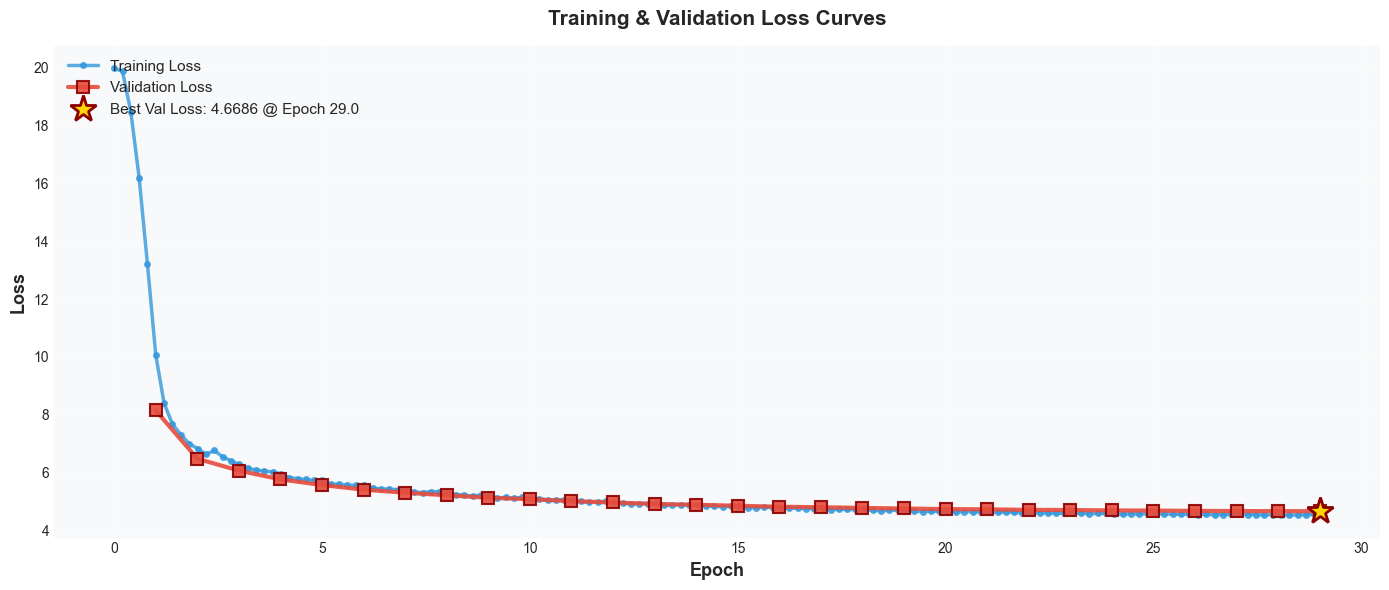

In [24]:
# ==================== PLOT 1: Training & Validation Loss ====================

if len(train_data.get('loss', [])) > 0 and len(eval_data.get('eval_loss', [])) > 0:
    fig, ax = plt.subplots(figsize=(14, 6))

    # Plot training loss
    ax.plot(train_data['epoch'], train_data['loss'],
            'o-', label='Training Loss',
            color='#3498db', linewidth=2.5, markersize=4, alpha=0.8)

    # Plot validation loss
    ax.plot(eval_data['epoch'], eval_data['eval_loss'],
            's-', label='Validation Loss',
            color='#e74c3c', linewidth=3, markersize=8,
            markeredgecolor='darkred', markeredgewidth=1.5, alpha=0.9)

    # Highlight best validation loss
    best_val_idx = np.argmin(eval_data['eval_loss'])
    best_val_epoch = eval_data['epoch'][best_val_idx]
    best_val_loss = eval_data['eval_loss'][best_val_idx]

    ax.plot(best_val_epoch, best_val_loss,
            '*', color='gold', markersize=20,
            markeredgecolor='darkred', markeredgewidth=2,
            label=f'Best Val Loss: {best_val_loss:.4f} @ Epoch {best_val_epoch:.1f}',
            zorder=5)

    ax.set_xlabel('Epoch', fontsize=13, fontweight='bold')
    ax.set_ylabel('Loss', fontsize=13, fontweight='bold')
    ax.set_title('Training & Validation Loss Curves', fontsize=15, fontweight='bold', pad=15)
    ax.legend(fontsize=11, loc='upper left', framealpha=0.95, fancybox=True, shadow=True)
    ax.grid(True, alpha=0.35, linestyle='--', linewidth=0.7)
    ax.set_facecolor('#f8f9fa')

    plt.tight_layout()
    plot1_path = output_dir / 'plot1_loss_curves.png'
    plt.savefig(plot1_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✓ Plot 1 saved: {plot1_path}")
    plt.show()
else:
    print("⚠️  Insufficient training data for loss curves plot")

✓ Plot 2 saved: outputs\banglat5_final_20260325_023556\plot2_all_metrics_over_epochs.png


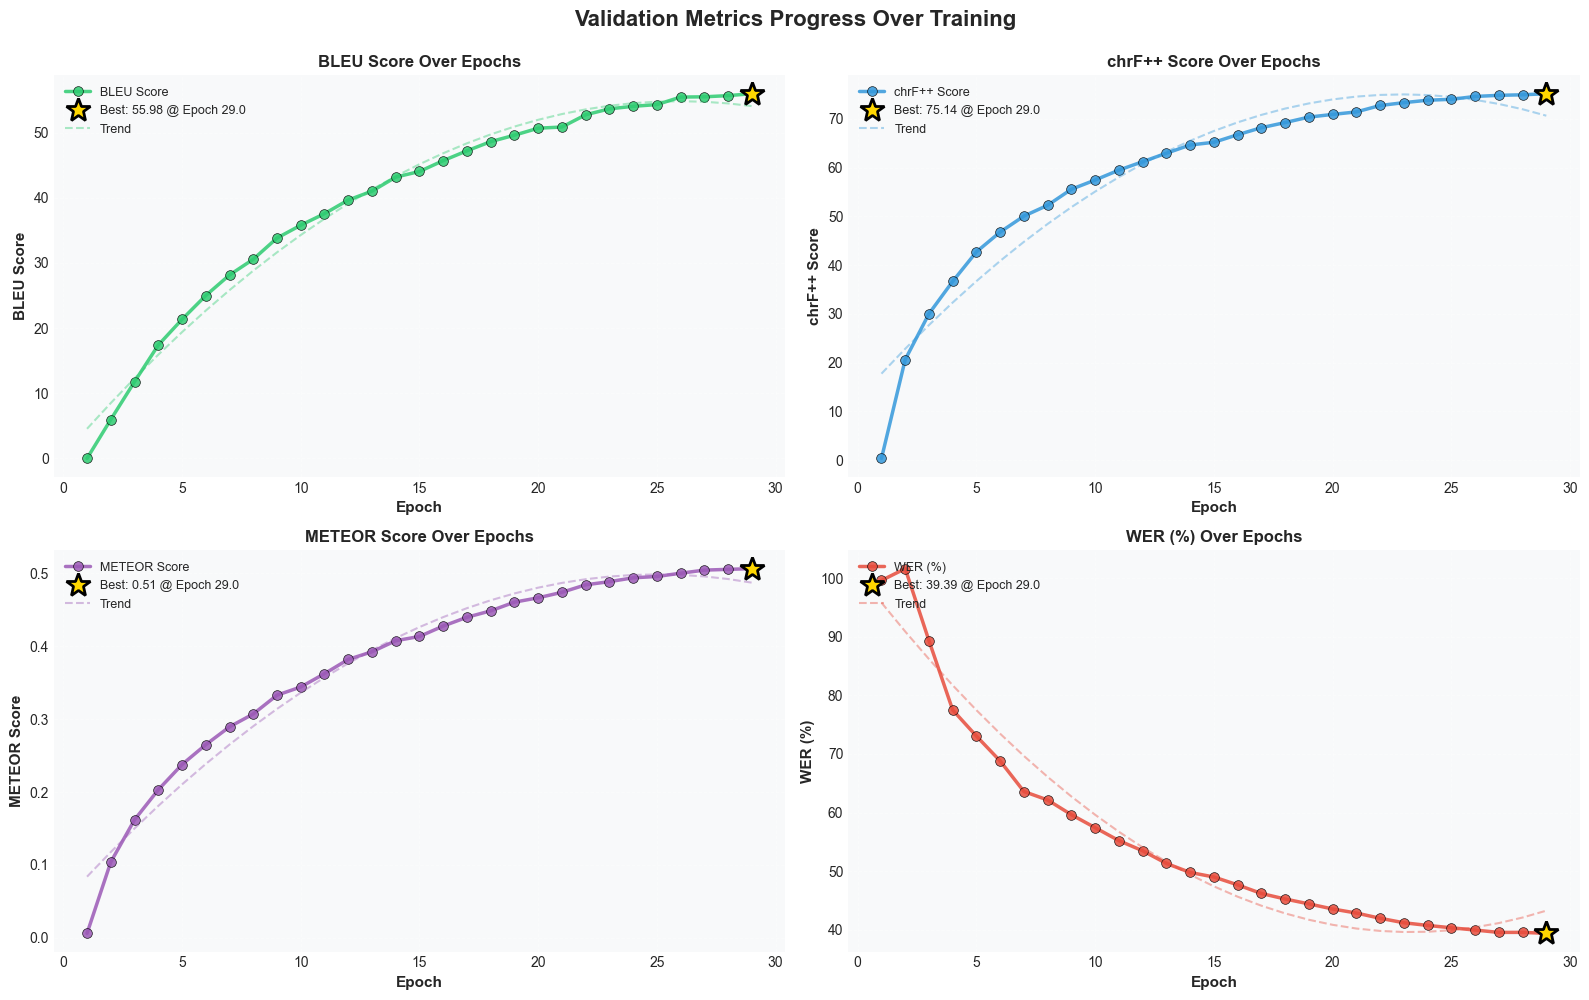

In [25]:
# ==================== PLOT 2: All Validation Metrics Over Epochs ====================

if len(eval_data.get('eval_bleu', [])) > 0:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('Validation Metrics Progress Over Training',
                 fontsize=16, fontweight='bold', y=0.995)
    fig.patch.set_facecolor('white')

    # Define metrics to plot
    metrics_config = [
        ('eval_bleu', 'BLEU Score', '#2ecc71', 'max'),
        ('eval_chrf', 'chrF++ Score', '#3498db', 'max'),
        ('eval_meteor', 'METEOR Score', '#9b59b6', 'max'),
        ('eval_wer', 'WER (%)', '#e74c3c', 'min'),
    ]

    for idx, (metric_key, metric_name, color, best_type) in enumerate(metrics_config):
        row = idx // 2
        col = idx % 2
        ax = axes[row, col]
        ax.set_facecolor('#f8f9fa')

        # Plot metric
        ax.plot(eval_data['epoch'], eval_data[metric_key],
                'o-', label=metric_name,
                color=color, linewidth=2.5, markersize=7,
                markeredgecolor='black', markeredgewidth=0.5, alpha=0.85)

        # Find and highlight best value
        if best_type == 'max':
            best_idx = np.argmax(eval_data[metric_key])
        else:  # min
            best_idx = np.argmin(eval_data[metric_key])

        best_epoch = eval_data['epoch'][best_idx]
        best_value = eval_data[metric_key][best_idx]

        ax.plot(best_epoch, best_value,
                '*', color='gold', markersize=18,
                markeredgecolor='black', markeredgewidth=2,
                label=f'Best: {best_value:.2f} @ Epoch {best_epoch:.1f}',
                zorder=5)

        # Add trend line (polynomial fit)
        if len(eval_data['epoch']) >= 3:
            z = np.polyfit(eval_data['epoch'], eval_data[metric_key], 2)
            p = np.poly1d(z)
            ax.plot(eval_data['epoch'], p(eval_data['epoch']),
                    '--', color=color, linewidth=1.5, alpha=0.4, label='Trend')

        ax.set_xlabel('Epoch', fontsize=11, fontweight='bold')
        ax.set_ylabel(metric_name, fontsize=11, fontweight='bold')
        ax.set_title(f'{metric_name} Over Epochs', fontsize=12, fontweight='bold')
        ax.legend(fontsize=9, loc='upper left', framealpha=0.95, fancybox=True, shadow=True)
        ax.grid(True, alpha=0.35, linestyle='--', linewidth=0.7)

    plt.tight_layout()
    plot2_path = output_dir / 'plot2_all_metrics_over_epochs.png'
    plt.savefig(plot2_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✓ Plot 2 saved: {plot2_path}")
    plt.show()
else:
    print("⚠️  Insufficient evaluation data for metrics over epochs plot")

---
## Plot 3: Combined Metrics Convergence

Normalized view of all metrics on the same scale (0-100)

✓ Plot 3 saved: outputs\banglat5_final_20260325_023556\plot3_combined_metrics_convergence.png


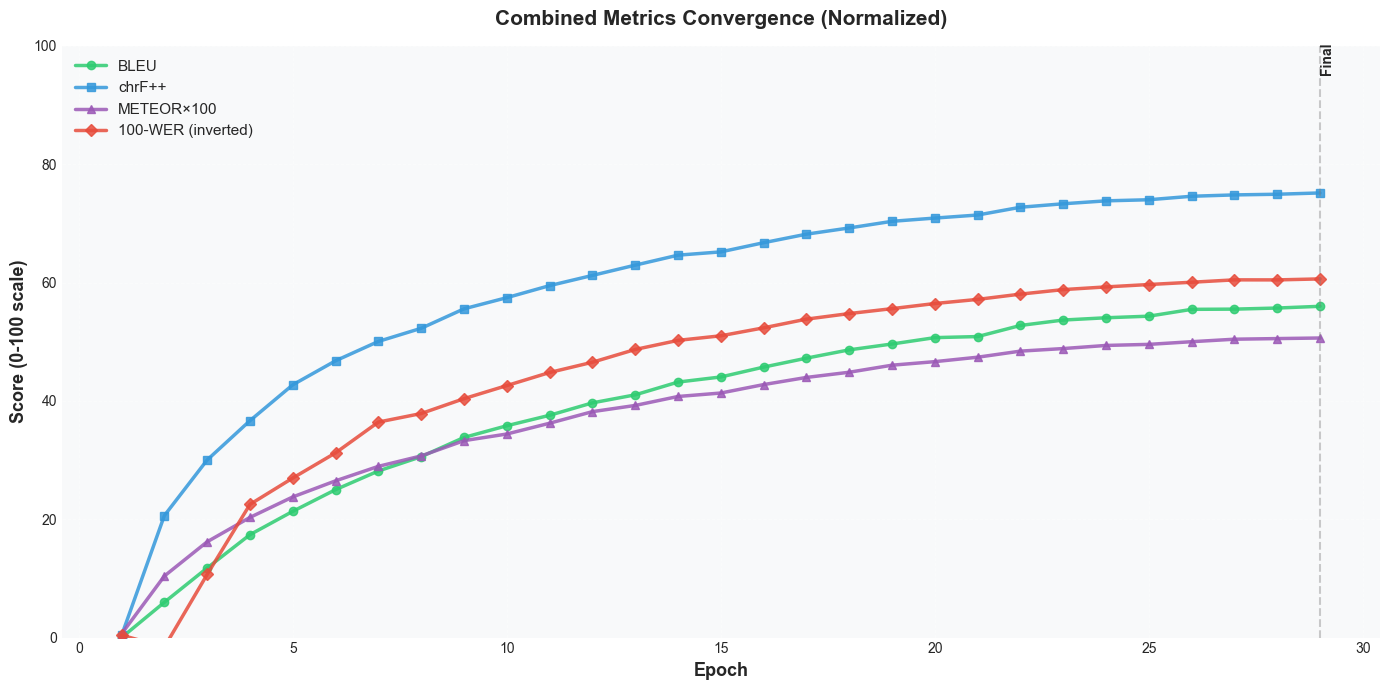

In [26]:
# ==================== PLOT 3: Combined Metrics Convergence ====================

if len(eval_data.get('eval_bleu', [])) > 0:
    fig, ax = plt.subplots(figsize=(14, 7))
    ax.set_facecolor('#f8f9fa')

    # Normalize metrics to 0-100 scale for comparison
    # BLEU (already 0-100)
    ax.plot(eval_data['epoch'], eval_data['eval_bleu'],
            'o-', label='BLEU', color='#2ecc71',
            linewidth=2.5, markersize=6, alpha=0.85)

    # chrF++ (already 0-100)
    ax.plot(eval_data['epoch'], eval_data['eval_chrf'],
            's-', label='chrF++', color='#3498db',
            linewidth=2.5, markersize=6, alpha=0.85)

    # METEOR (0-1, multiply by 100)
    meteor_scaled = eval_data['eval_meteor'] * 100
    ax.plot(eval_data['epoch'], meteor_scaled,
            '^-', label='METEOR×100', color='#9b59b6',
            linewidth=2.5, markersize=6, alpha=0.85)

    # WER (0-100, but lower is better - invert for visualization)
    wer_inverted = 100 - eval_data['eval_wer']
    ax.plot(eval_data['epoch'], wer_inverted,
            'D-', label='100-WER (inverted)', color='#e74c3c',
            linewidth=2.5, markersize=6, alpha=0.85)

    ax.set_xlabel('Epoch', fontsize=13, fontweight='bold')
    ax.set_ylabel('Score (0-100 scale)', fontsize=13, fontweight='bold')
    ax.set_title('Combined Metrics Convergence (Normalized)',
                 fontsize=15, fontweight='bold', pad=15)
    ax.legend(fontsize=11, loc='upper left', framealpha=0.95, fancybox=True, shadow=True)
    ax.grid(True, alpha=0.35, linestyle='--', linewidth=0.7)
    ax.set_ylim(0, 100)

    # Add convergence annotation
    if len(eval_data['epoch']) >= 2:
        final_epoch = eval_data['epoch'][-1]
        ax.axvline(final_epoch, color='gray', linestyle='--', linewidth=1.5, alpha=0.4)
        ax.text(final_epoch, 95, 'Final',
                rotation=90, verticalalignment='bottom', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plot3_path = output_dir / 'plot3_combined_metrics_convergence.png'
    plt.savefig(plot3_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✓ Plot 3 saved: {plot3_path}")
    plt.show()
else:
    print("⚠️  Insufficient evaluation data for combined convergence plot")

---
## Plot 4: Overfitting Detection

Dual-axis plots showing metrics vs loss to detect overfitting patterns

✓ Plot 4 saved: outputs\banglat5_final_20260325_023556\plot4_overfitting_detection.png


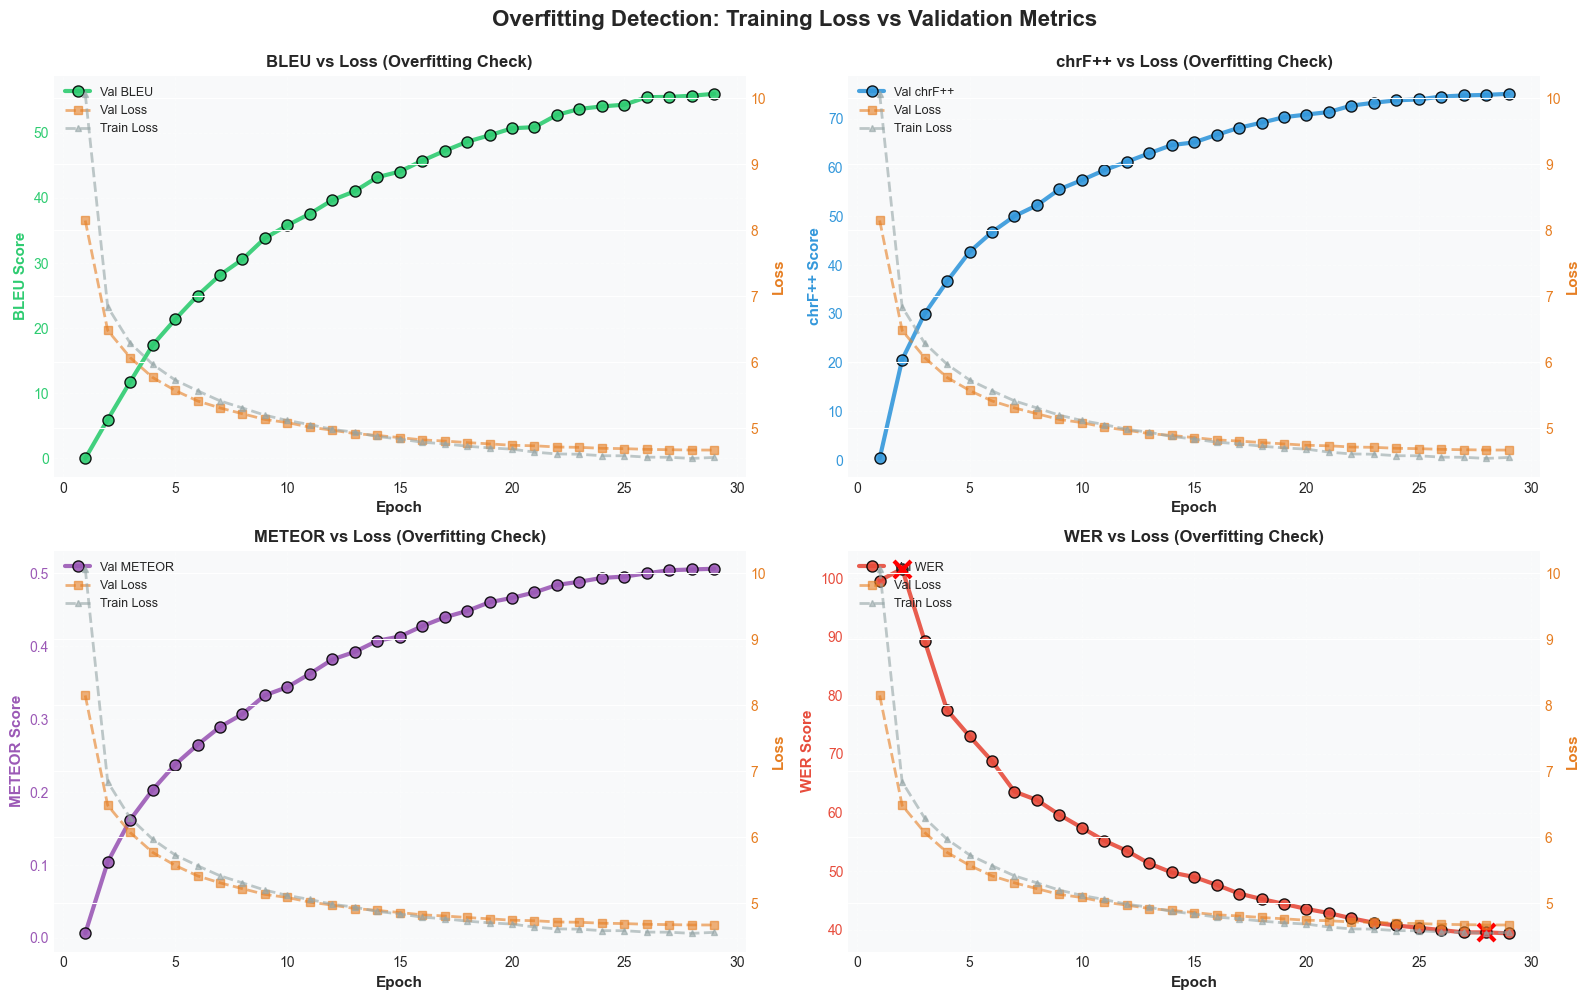

In [27]:
# ==================== PLOT 4: Individual Metric Progress (Overfitting Detection) ====================

if len(train_data.get('loss', [])) > 0 and len(eval_data.get('eval_bleu', [])) > 0:
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('Overfitting Detection: Training Loss vs Validation Metrics',
                 fontsize=16, fontweight='bold', y=0.995)
    fig.patch.set_facecolor('white')

    # Interpolate training loss at evaluation epochs
    train_loss_at_eval = np.interp(eval_data['epoch'],
                                     train_data['epoch'],
                                     train_data['loss'])

    # Plot configurations
    plot_configs = [
        ('BLEU', 'eval_bleu', '#2ecc71', 'max'),
        ('chrF++', 'eval_chrf', '#3498db', 'max'),
        ('METEOR', 'eval_meteor', '#9b59b6', 'max'),
        ('WER', 'eval_wer', '#e74c3c', 'min'),
    ]

    for idx, (name, metric_key, color, best_type) in enumerate(plot_configs):
        row = idx // 2
        col = idx % 2
        ax = axes[row, col]
        ax.set_facecolor('#f8f9fa')

        # Create twin axis for loss
        ax2 = ax.twinx()

        # Plot validation metric
        line1 = ax.plot(eval_data['epoch'], eval_data[metric_key],
                        'o-', label=f'Val {name}',
                        color=color, linewidth=3, markersize=8,
                        markeredgecolor='black', markeredgewidth=1, alpha=0.9)

        # Plot validation loss on secondary axis
        line2 = ax2.plot(eval_data['epoch'], eval_data['eval_loss'],
                         's--', label='Val Loss',
                         color='#e67e22', linewidth=2, markersize=6, alpha=0.6)

        # Plot training loss (interpolated)
        line3 = ax2.plot(eval_data['epoch'], train_loss_at_eval,
                        '^--', label='Train Loss',
                        color='#95a5a6', linewidth=2, markersize=5, alpha=0.6)

        # Detect overfitting
        if len(eval_data[metric_key]) >= 3:
            metric_diff = np.diff(eval_data[metric_key])
            loss_diff = np.diff(train_loss_at_eval)

            # Find potential overfitting points
            if best_type == 'max':
                overfitting_points = (metric_diff < 0) & (loss_diff < 0)
            else:
                overfitting_points = (metric_diff > 0) & (loss_diff < 0)

            if np.any(overfitting_points):
                overfitting_epochs = eval_data['epoch'][1:][overfitting_points]
                overfitting_values = eval_data[metric_key][1:][overfitting_points]

                ax.scatter(overfitting_epochs, overfitting_values,
                          color='red', s=150, marker='x', linewidths=3,
                          label='Potential Overfitting', zorder=10)

        # Styling
        ax.set_xlabel('Epoch', fontsize=11, fontweight='bold')
        ax.set_ylabel(f'{name} Score', fontsize=11, fontweight='bold', color=color)
        ax2.set_ylabel('Loss', fontsize=11, fontweight='bold', color='#e67e22')
        ax.set_title(f'{name} vs Loss (Overfitting Check)', fontsize=12, fontweight='bold')

        ax.tick_params(axis='y', labelcolor=color)
        ax2.tick_params(axis='y', labelcolor='#e67e22')

        # Combine legends
        lines = line1 + line2 + line3
        labels = [l.get_label() for l in lines]

        ax.legend(lines, labels, fontsize=9, loc='upper left', framealpha=0.95, fancybox=True, shadow=True)
        ax.grid(True, alpha=0.35, linestyle='--', linewidth=0.7)

    plt.tight_layout()
    plot4_path = output_dir / 'plot4_overfitting_detection.png'
    plt.savefig(plot4_path, dpi=300, bbox_inches='tight', facecolor='white')
    print(f"✓ Plot 4 saved: {plot4_path}")
    plt.show()
else:
    print("⚠️  Insufficient data for overfitting detection plot")

---
## Plot 5: Final Results Comparison

Compare validation, in-domain test, and out-of-domain test performance

✓ Plot 5 saved: outputs\banglat5_final_20260325_023556\plot5_final_comparison.png


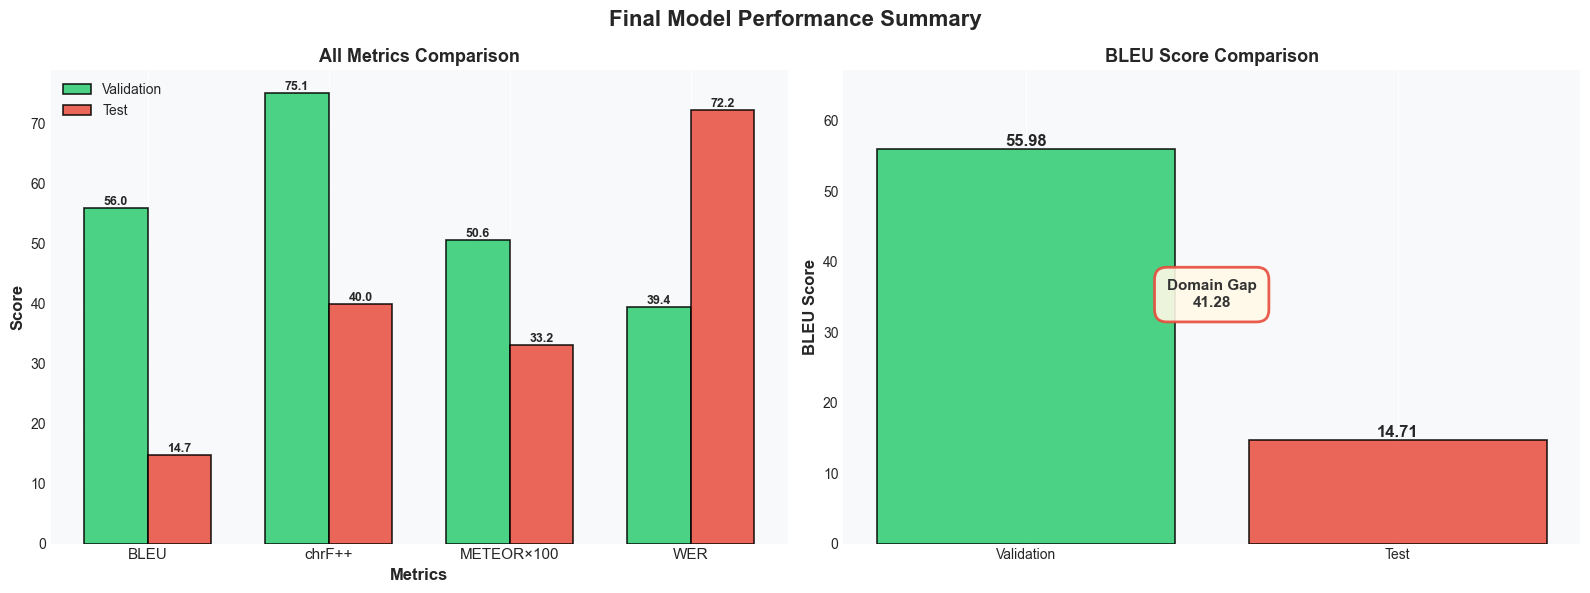

In [28]:
# ==================== PLOT 5: Final Results Comparison ====================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Final Model Performance Summary', fontsize=16, fontweight='bold')
fig.patch.set_facecolor('white')

# ===== Left: Grouped Bar Chart =====
metrics_names = ['BLEU', 'chrF++', 'METEOR×100', 'WER']

validation_scores = [val_bleu, val_chrf, val_meteor * 100, val_wer]
test_scores = [test_bleu, test_chrf, test_meteor * 100, test_wer]

x = np.arange(len(metrics_names))
width = 0.35

axes[0].set_facecolor('#f8f9fa')
bars1 = axes[0].bar(x - width/2, validation_scores, width,
                    label='Validation', color='#2ecc71', alpha=0.85, edgecolor='black', linewidth=1.2)
bars2 = axes[0].bar(x + width/2, test_scores, width,
                    label='Test', color='#e74c3c', alpha=0.85, edgecolor='black', linewidth=1.2)

axes[0].set_xlabel('Metrics', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Score', fontsize=12, fontweight='bold')
axes[0].set_title('All Metrics Comparison', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics_names, fontsize=11)
axes[0].legend(fontsize=10, loc='upper left', framealpha=0.95, fancybox=True, shadow=True)
axes[0].grid(axis='y', alpha=0.35, linestyle='--', linewidth=0.7)

# Add value labels
def add_value_labels(ax, bars):
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

add_value_labels(axes[0], bars1)
add_value_labels(axes[0], bars2)

# ===== Right: BLEU Score Focus =====
axes[1].set_facecolor('#f8f9fa')
bleu_labels = ['Validation', 'Test']
bleu_values = [val_bleu, test_bleu]
colors = ['#2ecc71', '#e74c3c']

bars = axes[1].bar(bleu_labels, bleu_values, color=colors, alpha=0.85,
                   edgecolor='black', linewidth=1.2)
axes[1].set_ylabel('BLEU Score', fontsize=12, fontweight='bold')
axes[1].set_title('BLEU Score Comparison', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, max(bleu_values) * 1.2)
axes[1].grid(axis='y', alpha=0.35, linestyle='--', linewidth=0.7)

# Add value labels
for bar in bars:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}',
                ha='center', va='bottom', fontsize=12, fontweight='bold')

# Add domain gap annotation as text box instead of arrow
domain_gap = val_bleu - test_bleu
mid_point = (val_bleu + test_bleu) / 2
axes[1].text(0.5, mid_point,
            f'Domain Gap\n{domain_gap:.2f}',
            ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.8', facecolor='#fff9e6',
                     edgecolor='#e74c3c', linewidth=2, alpha=0.9),
            fontsize=11, fontweight='bold', color='#333333')

plt.tight_layout()
plot5_path = output_dir / 'plot5_final_comparison.png'
plt.savefig(plot5_path, dpi=300, bbox_inches='tight', facecolor='white')
print(f"✓ Plot 5 saved: {plot5_path}")
plt.show()

---
## Visualization Summary

Overview of all generated plots and key statistics

In [29]:
# ==================== Visualization Summary ====================
print("\n" + "="*80)
print("📊 ALL PLOTS GENERATED")
print("="*80)

plots_generated = []

if (output_dir / 'plot1_loss_curves.png').exists():
    plots_generated.append("1. Loss Curves")
    print(f"\n✓ Plot 1: {output_dir / 'plot1_loss_curves.png'}")

if (output_dir / 'plot2_all_metrics_over_epochs.png').exists():
    plots_generated.append("2. All Metrics Over Epochs")
    print(f"✓ Plot 2: {output_dir / 'plot2_all_metrics_over_epochs.png'}")

if (output_dir / 'plot3_combined_metrics_convergence.png').exists():
    plots_generated.append("3. Combined Convergence")
    print(f"✓ Plot 3: {output_dir / 'plot3_combined_metrics_convergence.png'}")

if (output_dir / 'plot4_overfitting_detection.png').exists():
    plots_generated.append("4. Overfitting Detection")
    print(f"✓ Plot 4: {output_dir / 'plot4_overfitting_detection.png'}")

if (output_dir / 'plot5_final_comparison.png').exists():
    plots_generated.append("5. Final Comparison")
    print(f"✓ Plot 5: {output_dir / 'plot5_final_comparison.png'}")

print("="*80)

# Summary statistics
if len(eval_data.get('eval_bleu', [])) > 0:
    print("\n📈 TRAINING SUMMARY:")
    print(f"  Total training steps: {len(train_data.get('loss', []))}")
    print(f"  Evaluation checkpoints: {len(eval_data.get('eval_loss', []))}")
    print(f"  Best validation BLEU: {max(eval_data['eval_bleu']):.2f} @ Epoch {eval_data['epoch'][np.argmax(eval_data['eval_bleu'])]:.1f}")
    print(f"  Final validation BLEU: {eval_data['eval_bleu'][-1]:.2f}")
    print(f"  Best validation loss: {min(eval_data['eval_loss']):.4f}")

print("\n📊 FINAL RESULTS:")
print(f"  Validation BLEU: {val_bleu:.2f}")
print(f"  Test BLEU: {test_bleu:.2f}")
print(f"  Domain Gap: {val_bleu - test_bleu:+.2f} BLEU points")

print("\n✅ All visualizations complete!")
print(f"📁 Saved to: {output_dir}")


📊 ALL PLOTS GENERATED

✓ Plot 1: outputs\banglat5_final_20260325_023556\plot1_loss_curves.png
✓ Plot 2: outputs\banglat5_final_20260325_023556\plot2_all_metrics_over_epochs.png
✓ Plot 3: outputs\banglat5_final_20260325_023556\plot3_combined_metrics_convergence.png
✓ Plot 4: outputs\banglat5_final_20260325_023556\plot4_overfitting_detection.png
✓ Plot 5: outputs\banglat5_final_20260325_023556\plot5_final_comparison.png

📈 TRAINING SUMMARY:
  Total training steps: 145
  Evaluation checkpoints: 29
  Best validation BLEU: 55.98 @ Epoch 29.0
  Final validation BLEU: 55.98
  Best validation loss: 4.6686

📊 FINAL RESULTS:
  Validation BLEU: 55.98
  Test BLEU: 14.71
  Domain Gap: +41.28 BLEU points

✅ All visualizations complete!
📁 Saved to: outputs\banglat5_final_20260325_023556
